# Шаг 4. Температура: как модель выбирает следующий символ

Модель выдаёт только **вероятности** следующего символа. Как по ним выбирать — решаем мы.
Самая популярная «ручка» — **температура** T: перед softmax все сырые оценки делятся на T.

| T | Что происходит | Текст |
|---|----------------|-------|
| 0 | всегда самый вероятный вариант (жадный выбор) | одинаковый и часто зацикленный |
| < 1 | вероятные варианты становятся ещё вероятнее | аккуратный, но скучный |
| 1 | вероятности как есть | как в обучающих данных |
| > 1 | вероятности выравниваются | смелый, потом — бессмыслица |

Ту же ручку вы встречаете в настройках ChatGPT и других моделей. Важно: **сама модель при этом не меняется** — меняется только способ выбора.

**Структура примера (алгоритм):**
1. Смотрим, что температура делает с тремя числами.
2. Берём вероятности биграмм из шага 2 как «сырые оценки» (логарифм подсчётов).
3. Рисуем, как меняется распределение следующей буквы после «а» при разной температуре.
4. Придумываем имена при T = 0, 0.5, 1 и 2.
5. Измеряем, как температура меняет разнообразие и правдоподобие имён.

In [ ]:
# Настройка для Google Colab. На своём компьютере эта ячейка ничего не делает.
# В Colab нужна папка machine_vision на Google Диске (в ней session01–session05 и dataset).
import os
import sys

try:
    from google.colab import drive
except ImportError:
    drive = None

if drive:
    drive.mount("/content/drive")
    COLAB_ROOT = "/content/drive/MyDrive/machine_vision"
    os.chdir(f"{COLAB_ROOT}/session05")  # здесь лежит common.py и сохраняются результаты
    sys.path.insert(0, os.getcwd())

## Общий модуль `common.py`

Во всех примерах сессии используется модуль `common.py` из этой же папки:

| Имя | Что делает |
|-----|------------|
| `load_names()`, `load_text()` | русские имена из `names.txt` и «Евгений Онегин» (главы 1–8) из `onegin.txt` |
| `CharTokenizer(text)` | словарь символов: `encode` — строка → номера, `decode` — номера → строка, `vocab_size` — размер словаря |
| `name_tokenizer`, `bigram_pairs`, `bigram_counts` | словарь для имён (точка `.` — начало/конец имени), пары «буква → следующая», таблица подсчётов |
| `sample_name(probs, tok)` | придумать имя по таблице вероятностей |
| `apply_temperature(logits, T)` | вероятности из «сырых оценок» с температурой T |
| `MiniGPT`, `Block`, `SelfAttention` | маленький трансформер по символам |
| `save_gpt`, `load_gpt` | сохранить / загрузить GPT вместе со словарём |
| `load_session04()` | модуль `common.py` из сессии 4 (кошки и собаки, `SimpleCNN`) — для бонуса |
| `show()` | показать графики matplotlib |

> Запускайте примеры из папки `session05`, иначе `import common` не найдёт модуль.
> Библиотеки: `pip install -r requirements.txt`. Тексты лежат в этой же папке, интернет не нужен.

## 1. Температура на трёх числах

Пусть у модели три варианта с оценками 2, 1 и 0. Делим оценки на T и применяем softmax:
- при T = 1 вероятности 0.665, 0.245, 0.090 — как есть;
- при T = 0.25 оценки становятся 8, 4, 0 — разница между ними выросла в 4 раза, и почти всё достаётся первому;
- при T = 10 оценки 0.2, 0.1, 0 — почти одинаковые, и вероятности почти равны (по 1/3).

Порядок вариантов **никогда** не меняется: самый вероятный остаётся самым вероятным при любой T.

In [1]:
import matplotlib.pyplot as plt
import torch

from common import apply_temperature, bigram_counts, bigram_pairs, load_names, name_tokenizer, sample_name, show

names = load_names()
tok = name_tokenizer(names)
counts = bigram_counts(names, tok)
logits = torch.log(counts + 0.1)        # «сырые оценки»: softmax(logits) — это вероятности из шага 2

## 2. Логарифм подсчётов как сырые оценки

Чтобы воспользоваться температурой, нужны сырые оценки, а у нас в шаге 2 были сразу вероятности.
Возьмём `log(подсчёты + 0.1)`: softmax от них вернёт ровно вероятности шага 2 (softmax = экспонента и деление на сумму, экспонента отменяет логарифм).

In [2]:
# Сначала на трёх числах: оценки 2, 1, 0 → вероятности при разной температуре
z = torch.tensor([2.0, 1.0, 0.0])
print("Оценки:", z.tolist())
for t in [0, 0.25, 0.5, 1.0, 2.0, 10.0]:
    print(f"  T = {t:>4}: вероятности", ", ".join(f"{p:.3f}" for p in apply_temperature(z, t)))

Оценки: [2.0, 1.0, 0.0]
  T =    0: вероятности 1.000, 0.000, 0.000
  T = 0.25: вероятности 0.982, 0.018, 0.000
  T =  0.5: вероятности 0.867, 0.117, 0.016
  T =  1.0: вероятности 0.665, 0.245, 0.090
  T =  2.0: вероятности 0.506, 0.307, 0.186
  T = 10.0: вероятности 0.367, 0.332, 0.301


## 3. Распределение при разной температуре

При маленькой T почти вся вероятность уходит одной букве, при большой — столбики выравниваются.

T = 0.3: самый вероятный после «а» — «.» с вероятностью 0.92
T = 0.7: самый вероятный после «а» — «.» с вероятностью 0.52
T = 1.0: самый вероятный после «а» — «.» с вероятностью 0.35
T = 1.5: самый вероятный после «а» — «.» с вероятностью 0.22
T = 3.0: самый вероятный после «а» — «.» с вероятностью 0.11


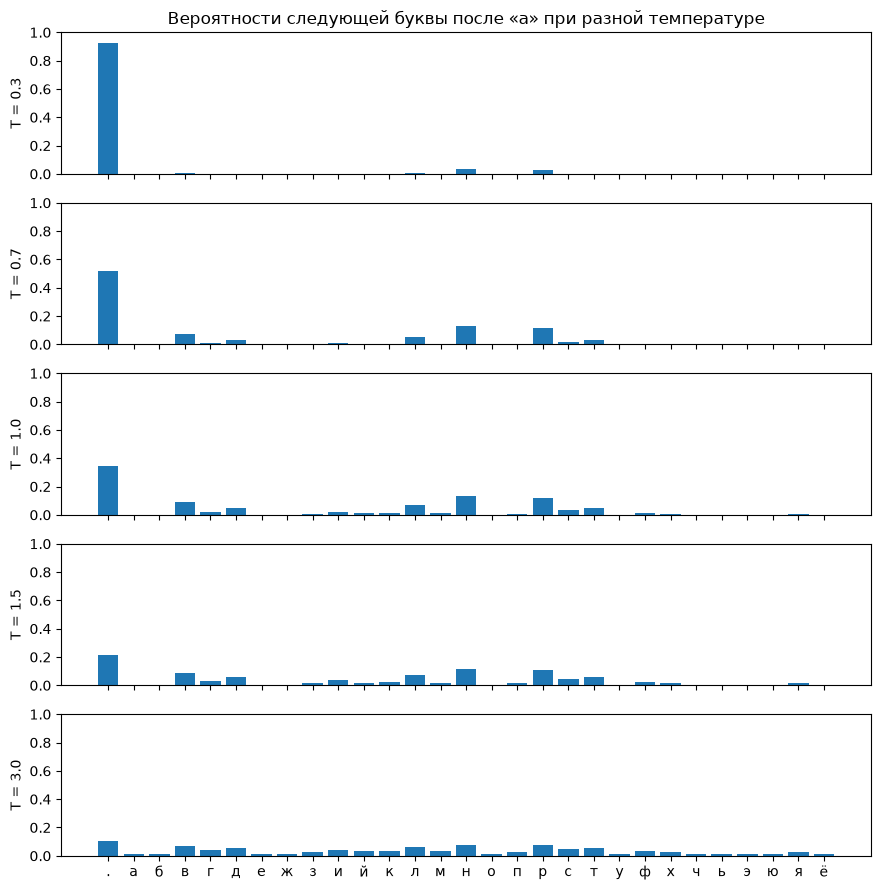

In [3]:
temperatures = [0.3, 0.7, 1.0, 1.5, 3.0]
letter = "а"
row = logits[tok.stoi[letter]]
fig, axes = plt.subplots(len(temperatures), 1, figsize=(9, 9), sharex=True)
for ax, t in zip(axes, temperatures):
    p = apply_temperature(row, t)
    ax.bar(tok.chars, p)
    ax.set_ylim(0, 1)
    ax.set_ylabel(f"T = {t}")
    top = p.argmax().item()
    print(f"T = {t}: самый вероятный после «{letter}» — «{tok.itos[top]}» с вероятностью {p[top]:.2f}")
axes[0].set_title(f"Вероятности следующей буквы после «{letter}» при разной температуре")
plt.tight_layout()
plt.savefig("temperature.png", dpi=100)
show()

## 4. Имена при разной температуре

При **T = 0** модель всегда выбирает самое вероятное: после точки — «а», после «а» — точку. Получается одно и то же имя «а».
При T = 0.5 имена короче и «правильнее», при T = 2 — набор букв.

In [4]:
g = torch.Generator().manual_seed(1)
for t in [0, 0.5, 1.0, 2.0]:
    probs = apply_temperature(logits, t)
    print(f"T = {t}: {', '.join(sample_name(probs, tok, g) for _ in range(12))}")

T = 0: а, а, а, а, а, а, а, а, а, а, а, а
T = 0.5: в, са, вавей, а, елегера, ана, а, верий, венаролланина, да, вег, вена
T = 1.0: ей, ияея, алас, вевафелюлиилья, дминтакслил, влий, я, мбория, аг, ветия, слегза, ифиза
T = 2.0: ламунмкрмад, знюмет, зйпжокмитвячеририфйё, вавборозуоий, эколивгда, ме, ви, яьйпфхнпвюжплийякоей, кстёчэдавакжесер, садес, вгдеси, ра


## 5. Качество против разнообразия

Придумаем по 500 имён при каждой температуре и измерим:
- **разных имён** — насколько модель изобретательна;
- **среднюю длину** — при низкой T модель торопится поставить самую вероятную после «а» точку, имена короткие;
- **штраф** — средний `−log(вероятность)` по честной модели с T = 1: насколько имена правдоподобны.

Видно, что это **размен**: чем выше температура, тем больше разных имён, но тем выше штраф (больше бессмыслицы).
Идеальной температуры нет — её выбирают под задачу: для ответа на контрольную — пониже, для стихов — повыше.

In [5]:
# Качество против разнообразия: 500 имён при каждой температуре.
# «Штраф» считаем по честной модели (T = 1): чем он меньше, тем правдоподобнее имена.
base = apply_temperature(logits, 1.0)
print("   T   разных имён из 500   средняя длина   штраф")
for t in [0, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0]:
    probs = apply_temperature(logits, t)
    batch = [sample_name(probs, tok, g) for _ in range(500)]
    xs, ys = bigram_pairs(batch, tok)
    penalty = -base[xs, ys].log().mean().item()
    length = sum(map(len, batch)) / len(batch)
    print(f"{t:4}   {len(set(batch)):18d}   {length:13.1f}   {penalty:5.2f}")

   T   разных имён из 500   средняя длина   штраф
   0                    1             1.0    1.46
 0.3                   81             1.8    1.59
 0.5                  247             3.2    1.80
 0.7                  350             5.0    1.99
 1.0                  414             6.3    2.32
 1.5                  462             8.7    2.86
 2.0                  479             9.9    3.26


## Попробуйте сами

1. Посмотрите распределение после другой буквы, например `letter = "о"` или `letter = "."`.
2. В пункте 1 поменяйте оценки на `[5.0, 1.0, 0.0]`. При какой температуре вероятности станут почти равными?
3. Найдите температуру, при которой имена вам нравятся больше всего. Какой у неё штраф и сколько разных имён в таблице пункта 5?
4. Ещё один способ выбора — **top-k**: оставить только k самых вероятных букв и выбирать среди них.
   Попробуйте написать его: `torch.topk(probs, k)` вернёт значения и номера.